[Download this notebook](lasso_vs_ols_ames_fa26.ipynb){download="lasso_vs_ols_ames_fa26.ipynb"} to run the code or borrow from it.

**The question.** Given exactly the same inputs, does LASSO predict sale prices better than ordinary least squares (OLS)?

- **OLS** minimizes $\text{RSS}$.
- **LASSO** minimizes $\text{RSS} + \lambda \sum_j |\beta_j|$. Its penalty shrinks coefficients and sets some to exactly 0. 
  
**The short answer.** Yes. LASSO had the higher test $R^2$ on 49 of 50 random train/test splits, using about half as many columns.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import make_column_transformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LassoCV, LinearRegression, RidgeCV
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", message="Found unknown categories")

BLUE, ORANGE, GRAY, INK = "#2a78d6", "#eb6834", "#c3c2b7", "#52514e"   # LASSO, OLS, background lines, reference lines
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.titlelocation": "left",
                     "axes.grid": True, "grid.color": "#e1e0d9", "axes.axisbelow": True, "legend.frameon": False})
dollars_k = lambda v, _: f"{v/1000:,.0f}k".replace("-", "−")

df = pd.read_csv("https://bryantstats.github.io/math460/data/ames_house_prices.csv")
y = df["SalePrice"].astype(float)
X = df.drop(columns="SalePrice")


def make_prep(min_frequency=10, scale_yes_no=False):
    """Standardize the numeric inputs. Turn each text input into 0/1 columns.
    Ames needs extra steps: it has blanks to fill and very rare categories to group."""
    numeric = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
    text = [SimpleImputer(strategy="constant", fill_value="None"),
            OneHotEncoder(drop="first", handle_unknown="infrequent_if_exist",
                          min_frequency=min_frequency, sparse_output=False)]
    if scale_yes_no:
        text.append(StandardScaler())
    return make_column_transformer(
        (numeric, make_column_selector(dtype_include="number")),
        (make_pipeline(*text), make_column_selector(dtype_exclude="number")),
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")


def scores(model, X, y):
    """Return R-squared and RMSE of a fitted model on the data given."""
    pred = model.predict(X)
    return r2_score(y, pred), mean_squared_error(y, pred) ** 0.5

# Part 1. Introduce the dataset

The **Ames Housing** data (De Cock, 2011) records home sales in Ames, Iowa, from 2006 to 2010. Each row is one sold house. We predict `SalePrice` in dollars, so this is a regression problem.

In [2]:
print("Rows:", X.shape[0], " Inputs:", X.shape[1])
print("Numeric inputs:", X.select_dtypes("number").shape[1], " Text inputs:", X.select_dtypes(exclude="number").shape[1])
print("Inputs with missing values:", int(X.isna().any().sum()))

Rows: 1460  Inputs: 79
Numeric inputs: 36  Text inputs: 43
Inputs with missing values: 19


In [3]:
df[["Neighborhood", "GrLivArea", "OverallQual", "YearBuilt", "KitchenQual", "SalePrice"]].head()

,Neighborhood,GrLivArea,OverallQual,YearBuilt,KitchenQual,SalePrice
0,CollgCr,1710,7,2003,Gd,208500
1,Veenker,1262,6,1976,TA,181500
2,CollgCr,1786,7,2001,Gd,223500
3,Crawfor,1717,7,1915,Gd,140000
4,NoRidge,2198,8,2000,Gd,250000


The inputs describe size, quality, location and condition:

| Input | Type | Meaning |
|:--|:--|:--|
| `GrLivArea` | Numeric | Above-ground living area (sq ft) |
| `OverallQual` | Numeric | Overall quality, rated 1 to 10 |
| `YearBuilt` | Numeric | Year of construction |
| `GarageCars` | Numeric | Garage capacity in cars |
| `Neighborhood` | Text | Location within Ames, such as `StoneBr` |
| `KitchenQual` | Text | Kitchen quality, from `Ex` (excellent) to `Fa` (fair) |
| `PoolQC` | Text | Pool quality, blank if there is no pool |

The data has 1,460 houses and 79 inputs. Prices have a long right tail, from \$34,900 to \$755,000, with a median of \$163,000. `OverallQual` and `GrLivArea` track price most closely among the numeric inputs. Many text inputs also have categories that almost no house belongs to: 69 of the 267 categories have fewer than 10 houses, which leaves regression very little data for estimating them.

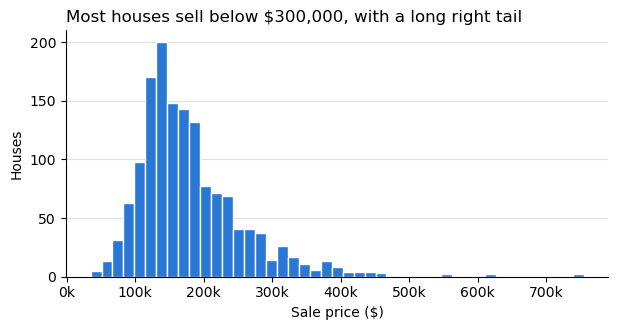

min     34900.0
50%    163000.0
max    755000.0


In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(y, bins=45, color=BLUE, edgecolor="#fcfcfb", linewidth=1)
ax.grid(axis="x", visible=False)
ax.set(xlabel="Sale price ($)", ylabel="Houses", title="Most houses sell below $300,000, with a long right tail")
ax.xaxis.set_major_formatter(dollars_k)
plt.show()
print(y.describe()[["min", "50%", "max"]].round(0).to_string())

In [5]:
# How strongly does each numeric input track the target? (top 5)
print(df.corr(numeric_only=True)["SalePrice"].drop("SalePrice").sort_values(key=abs, ascending=False).head(5).round(3).to_string())

OverallQual    0.791
GrLivArea      0.709
GarageCars     0.640
GarageArea     0.623
TotalBsmtSF    0.614


In [6]:
# Rare categories: categories with fewer than 10 houses
text_inputs = X.select_dtypes(exclude="number").columns
print("Categories across all text inputs:", sum(X[c].fillna("None").nunique() for c in text_inputs))
print("Categories with fewer than 10 houses:", sum((X[c].fillna("None").value_counts() < 10).sum() for c in text_inputs))

Categories across all text inputs: 267
Categories with fewer than 10 houses: 69


# Part 2. Explain the testing procedure

The same procedure is used for both models, so the contest is fair.

| Step | What happens | Why |
|:--|:--|:----|
| 1. Split | Randomly assign 70% of houses to training and 30% to test | The test set shows performance on houses the model hasn't seen |
| 2. Prepare inputs | Learn all preparation from the training houses only, then apply it to the test houses (the pipeline does this) | Prevents test information from leaking in |
| 3. Fit OLS | Fit on the training houses | There is nothing to tune |
| 4. Tune and fit LASSO | Choose `alpha` by 5-fold cross-validation **within the training houses**, then refit | The test set plays no part in choosing `alpha` |
| 5. Score | Compute test $R^2$ and RMSE for both models | Same test houses for both, so any difference comes from the models |
| 6. Repeat | Run steps 1 to 5 on **50 random splits** (`random_state` = 1 to 50) | One split can be lucky |

**Preparing the inputs.** Neither model gets squares or interactions.

- **Numeric inputs:** fill missing values with the training median, then standardize, so the LASSO penalty treats them on the same scale.
- **Text inputs:** a blank usually means the feature is absent, so it becomes the category `None`. Each text input then becomes 0/1 columns, one per category except a baseline.
- **Rare categories:** any category with fewer than 10 training houses is merged into an `infrequent` group for that input. 

In [7]:
print("Columns after preprocessing:", make_prep().fit_transform(X).shape[1])
print("Training rows:", len(train_test_split(X, test_size=0.3, random_state=1)[0]))
print("Test rows:", len(train_test_split(X, test_size=0.3, random_state=1)[1]))

Columns after preprocessing: 216
Training rows: 1022
Test rows: 438


The models see more columns than there are raw inputs because each text input becomes several 0/1 columns. The 216 above counts all 1,460 houses. The count depends on the training houses, because of the rare-category grouping, so it's 207 on the split used in Part 3 and about 206 on average.

# Part 3. OLS results, tuning alpha, and LASSO coefficients

This part walks through a single split (`random_state=1`). Part 4 repeats everything on all 50 splits.

## 3a. OLS

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

In [9]:
ols = make_pipeline(make_prep(), LinearRegression()).fit(X_train, y_train)
print("OLS train R2 = %.3f, RMSE = %.2f" % scores(ols, X_train, y_train))
print("OLS test  R2 = %.3f, RMSE = %.2f" % scores(ols, X_test, y_test))

names = ols[0].get_feature_names_out()
ols_coef = pd.Series(ols[-1].coef_, index=names)
print("\n10 largest OLS coefficients:")
print(ols_coef.sort_values(key=abs, ascending=False).head(10).round(3).to_string())

OLS train R2 = 0.904, RMSE = 23865.54
OLS test  R2 = 0.841, RMSE = 33718.76

10 largest OLS coefficients:
PoolQC_infrequent_sklearn       -949008.142
Utilities_infrequent_sklearn     -71275.257
PoolArea                          54486.187
Neighborhood_StoneBr              49388.591
Neighborhood_Edwards             -42370.593
Neighborhood_OldTown             -40587.167
Neighborhood_IDOTRR              -35486.169
GarageQual_infrequent_sklearn     34750.044
ExterQual_infrequent_sklearn     -34090.934
ExterQual_TA                     -33502.449


OLS uses all 207 columns. Its $R^2$ falls from 0.904 on the training houses to 0.841 on the test houses. This also happens to be a good split for OLS, whose median test $R^2$ over 50 splits is 0.791 (Part 4). Its largest coefficient is about −\$949,000, which looks wrong for a single feature of a house. Part 5 comes back to it.

## 3b. Tuning alpha for LASSO

`LassoCV` tries 100 values of `alpha`. For each one, it fits on 4 of 5 folds of the training houses and measures the error on the fifth, rotating through all five. It then picks the `alpha` with the lowest average error.

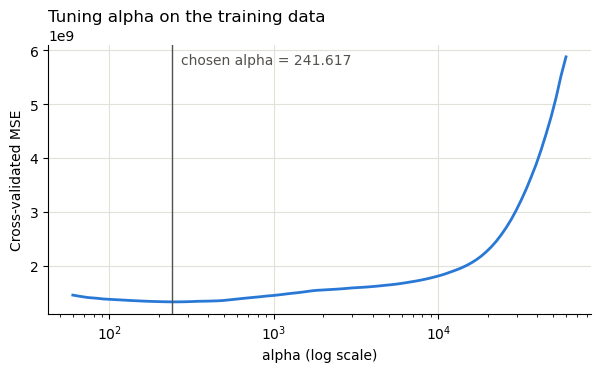

Chosen alpha: 241.617
LASSO train R2 = 0.868, RMSE = 27989.39
LASSO test  R2 = 0.870, RMSE = 30490.77


In [10]:
lasso = make_pipeline(make_prep(), LassoCV(cv=5, random_state=1, max_iter=50000)).fit(X_train, y_train)
cv = lasso[-1]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(cv.alphas_, cv.mse_path_.mean(axis=1), color=BLUE, lw=2)
ax.axvline(cv.alpha_, color=INK, lw=1)
ax.annotate(f"chosen alpha = {cv.alpha_:.3f}", (cv.alpha_, ax.get_ylim()[1]), xytext=(6, -14),
            textcoords="offset points", color=INK)
ax.set_xscale("log")
ax.set(xlabel="alpha (log scale)", ylabel="Cross-validated MSE", title="Tuning alpha on the training data")
plt.show()

print("Chosen alpha: %.3f" % cv.alpha_)
print("LASSO train R2 = %.3f, RMSE = %.2f" % scores(lasso, X_train, y_train))
print("LASSO test  R2 = %.3f, RMSE = %.2f" % scores(lasso, X_test, y_test))

The error falls a little as `alpha` grows from very small values, reaches a minimum at `alpha` = 242, then climbs quickly.

- **Too small:** the model is close to OLS and keeps noise columns.
- **Too large:** useful columns are shrunk or removed, so the model underfits.
- **The result on this split:** LASSO gives up some training fit (0.868 vs 0.904) and scores higher on the test houses (0.870 vs 0.841).

## 3c. Plot the LASSO coefficients

For a numeric input, a coefficient is the change in predicted price for 1 SD more of that input. For a 0/1 column, it is the difference from that input's baseline category. Numeric and 0/1 columns are in different units, so compare their bar lengths with care.

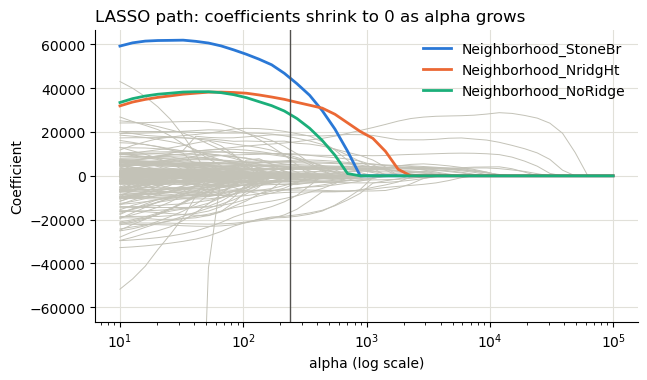

In [11]:
# Path plot: refit Lasso at many alphas on the prepared training data
Z_train = make_prep().fit_transform(X_train)
alphas = np.logspace(1, 5, 40)   # choose a range around the chosen alpha, up to where everything is 0
path = pd.DataFrame([Lasso(alpha=a, max_iter=50000).fit(Z_train, y_train).coef_ for a in alphas],
                    index=alphas, columns=Z_train.columns)

lasso_coef = pd.Series(lasso[-1].coef_, index=names)
highlight = lasso_coef.sort_values(key=abs, ascending=False).head(3).index   # the rest are drawn in gray

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(path.index, path.drop(columns=highlight).values, color=GRAY, lw=0.7)
for term, color in zip(highlight, [BLUE, ORANGE, "#1baf7a"]):
    ax.plot(path.index, path[term], color=color, lw=2, label=term)
ax.axvline(cv.alpha_, color=INK, lw=1)
ax.set_xscale("log"); ax.legend()
m = lasso_coef.abs().max()
ax.set_ylim(-1.5 * m, 1.5 * m)   # zoom in: at very small alpha, a few unstable coefficients run far off the chart
ax.set(xlabel="alpha (log scale)", ylabel="Coefficient", title="LASSO path: coefficients shrink to 0 as alpha grows")
plt.show()

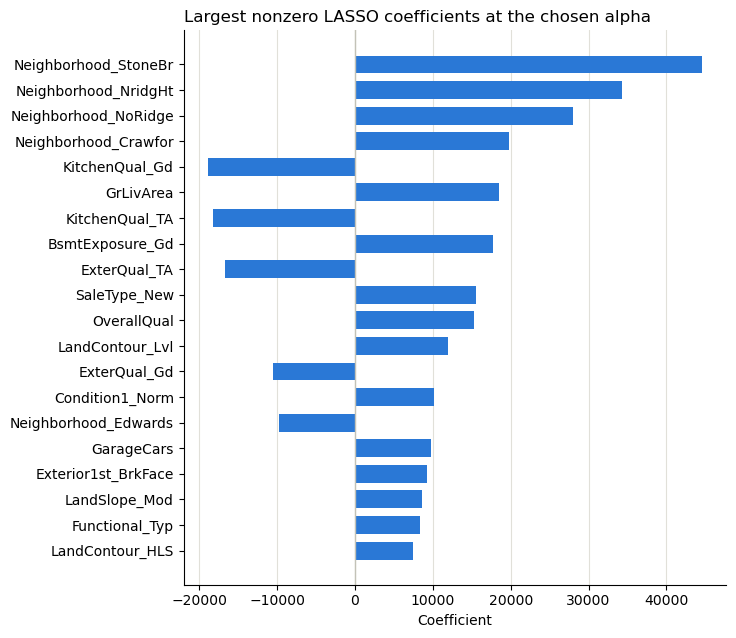

LASSO kept 82 of 207 columns


In [12]:
# Bar chart of the nonzero coefficients at the chosen alpha (just the 20 largest, since Ames keeps many)
kept = lasso_coef[lasso_coef != 0].sort_values(key=abs).tail(20)

fig, ax = plt.subplots(figsize=(7, 0.3 * len(kept) + 1.2))
ax.barh(kept.index, kept.values, color=BLUE, height=0.7)
ax.axvline(0, color=GRAY, lw=1); ax.grid(axis="y", visible=False)
ax.set(xlabel="Coefficient", title="Largest nonzero LASSO coefficients at the chosen alpha")
plt.show()

print(f"LASSO kept {(lasso_coef != 0).sum()} of {len(lasso_coef)} columns")

- **The path:** as `alpha` grows, coefficients shrink and reach 0 at different points. A few grow first, because they take over from related columns that have dropped out.
- **Location matters most:** the largest coefficients are for high-priced neighborhoods such as `StoneBr` and `NridgHt`, compared with the baseline neighborhood.
- **A negative bar isn't always a bad feature:** `KitchenQual_Gd` is negative because it compares with the baseline, an excellent kitchen.

# Part 4. Compare OLS and tuned LASSO

This repeats the procedure from Part 2 on 50 random splits, with `alpha` retuned on each one.

In [13]:
rows, ols_coefs, lasso_coefs = [], {}, {}
for seed in range(1, 51):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.3, random_state=seed)
    m_ols = make_pipeline(make_prep(), LinearRegression()).fit(Xa, ya)
    m_lasso = make_pipeline(make_prep(), LassoCV(cv=5, random_state=1, max_iter=50000)).fit(Xa, ya)

    names_s = m_ols[0].get_feature_names_out()
    ols_coefs[seed] = pd.Series(m_ols[-1].coef_, index=names_s)
    lasso_coefs[seed] = pd.Series(m_lasso[-1].coef_, index=names_s)
    rows.append({"seed": seed,
                 "ols_train": scores(m_ols, Xa, ya)[0], "lasso_train": scores(m_lasso, Xa, ya)[0],
                 "ols_r2": scores(m_ols, Xb, yb)[0], "lasso_r2": scores(m_lasso, Xb, yb)[0],
                 "ols_rmse": scores(m_ols, Xb, yb)[1], "lasso_rmse": scores(m_lasso, Xb, yb)[1],
                 "alpha": m_lasso[-1].alpha_, "kept": (m_lasso[-1].coef_ != 0).sum(), "columns": len(names_s)})
res = pd.DataFrame(rows).set_index("seed")
ols_coefs, lasso_coefs = pd.DataFrame(ols_coefs), pd.DataFrame(lasso_coefs)

table = pd.DataFrame({
    "median test R2": [res.ols_r2.median(), res.lasso_r2.median()],
    "worst test R2": [res.ols_r2.min(), res.lasso_r2.min()],
    "median test RMSE": [res.ols_rmse.median(), res.lasso_rmse.median()],
    "avg train-test gap": [(res.ols_train - res.ols_r2).mean(), (res.lasso_train - res.lasso_r2).mean()],
}, index=["OLS", "LASSO"]).round(3)
print(table.to_string())
print("\nLASSO higher test R2 on", (res.lasso_r2 > res.ols_r2).sum(), "of 50 splits")
print("Median alpha: %.3f   Average columns kept: %.1f of %.1f" % (res.alpha.median(), res.kept.mean(), res["columns"].mean()))

       median test R2  worst test R2  median test RMSE  avg train-test gap
OLS             0.791         -1.254         35877.785               0.233
LASSO           0.839          0.578         32402.011               0.094

LASSO higher test R2 on 49 of 50 splits
Median alpha: 148.125   Average columns kept: 101.9 of 206.1


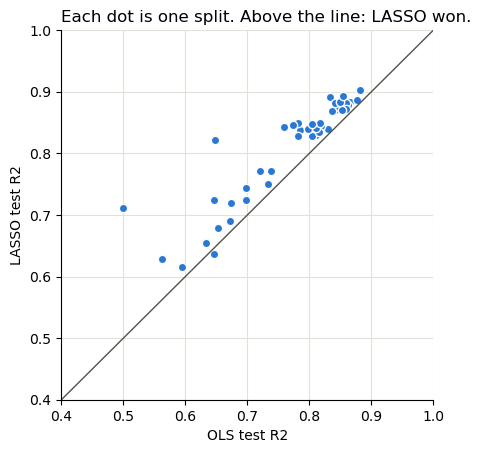

Splits off the chart (OLS test R2 below 0.4): 4


In [14]:
# Each dot is one split. Set the limits to fit your results.
# Ames stops at 0.4 because a few OLS splits fall far below that.
lim = [0.4, 1]
fig, ax = plt.subplots(figsize=(4.8, 4.8))
ax.scatter(res.ols_r2, res.lasso_r2, color=BLUE, s=36, edgecolor="#fcfcfb", lw=1)
ax.plot(lim, lim, color=INK, lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set(xlabel="OLS test R2", ylabel="LASSO test R2", title="Each dot is one split. Above the line: LASSO won.")
plt.show()
print("Splits off the chart (OLS test R2 below 0.4):", (res.ols_r2 < 0.4).sum())

# Part 5. Summarize the variables in the two models

OLS uses every column. LASSO keeps some and sets the rest to 0. Which columns it keeps depends partly on the split, so the table also counts how often each one was kept over all 50.

In [15]:
# In Ames, a rare category can be grouped on one split and not on another, so column names differ
# across splits. fillna(0) counts a missing column as "not kept". Without it, NaN != 0 would count as kept.
pct_kept = (lasso_coefs.fillna(0) != 0).mean(axis=1) * 100
summary = pd.DataFrame({"ols_coef": ols_coef, "lasso_coef": lasso_coef, "pct_kept": pct_kept}).dropna()
summary = summary.sort_values("pct_kept", ascending=False).round(3) + 0.0   # + 0.0 turns -0.0 into 0.0
print(summary.head(15).to_string())

print("\nOLS uses:", len(ols_coef), "  LASSO keeps (Part 3 split):", (lasso_coef != 0).sum())
print("Kept on all 50:", (pct_kept == 100).sum(), "  Kept on none:", (pct_kept == 0).sum(), "  Columns seen:", len(pct_kept))

                       ols_coef  lasso_coef  pct_kept
Neighborhood_NoRidge  22685.103   28003.524     100.0
BsmtFinType1_GLQ       5333.747    3392.417     100.0
Functional_Typ        17424.659    8291.752     100.0
LotFrontage           -1769.511   -3590.807     100.0
FullBath               5013.397    4022.757     100.0
BsmtQual_Gd          -14922.510   -5672.930     100.0
BsmtQual_TA          -10475.585     -17.235     100.0
OverallCond            4752.313    5968.615     100.0
Condition1_Norm        3958.966   10123.814     100.0
ScreenPorch            2661.670    2900.284     100.0
KitchenAbvGr          -2426.526   -2844.026     100.0
Fireplaces             4858.265    4025.240     100.0
OverallQual            8824.119   15256.144     100.0
KitchenQual_Gd       -21416.601  -18838.909     100.0
MSSubClass            -4854.021   -7419.386     100.0

OLS uses: 207   LASSO keeps (Part 3 split): 82
Kept on all 50: 29   Kept on none: 23   Columns seen: 223


OLS uses 207 columns on this split, and LASSO keeps 82. Over the 50 splits, 29 columns are kept every time, including `OverallQual` and the top neighborhoods, which makes sense for house prices. Another 23 are never kept.

**Which columns does LASSO drop?** The next table shows columns with noticeable OLS coefficients and a LASSO coefficient of 0.

In [16]:
# Noticeable in OLS, zero in LASSO. train_rows counts the training rows where a 0/1 column equals 1.
dropped = summary[summary.lasso_coef == 0].sort_values("ols_coef", key=abs, ascending=False).head(6).copy()
dropped["train_rows"] = [int(Z_train[c].sum()) if set(Z_train[c].unique()) <= {0, 1} else "numeric" for c in dropped.index]
print(dropped.to_string())

                                 ols_coef  lasso_coef  pct_kept  train_rows
PoolQC_infrequent_sklearn     -949008.142         0.0       0.0           4
Utilities_infrequent_sklearn   -71275.257         0.0       0.0           1
Neighborhood_IDOTRR            -35486.169         0.0      14.0          22
GarageQual_infrequent_sklearn   34750.044         0.0      26.0           5
ExterQual_infrequent_sklearn   -34090.934         0.0       2.0           7
Neighborhood_SWISU             -32283.804         0.0       8.0          23


Original inputs used by OLS: 79   by LASSO: 59
Dropped completely by LASSO: 1stFlrSF, Alley, BsmtFinSF1, BsmtFinSF2, BsmtUnfSF, CentralAir, Condition2, Electrical, ExterCond, Fence, GarageArea, GarageYrBlt, Heating, LowQualFinSF, MiscFeature, PavedDrive, PoolQC, RoofMatl, Street, Utilities


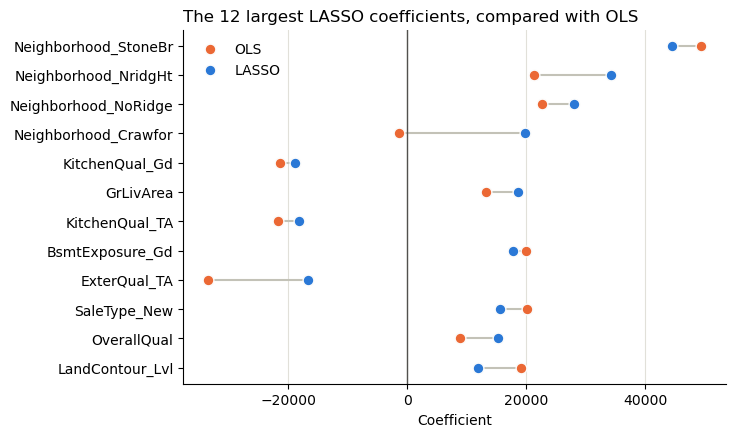

In [18]:
# How each model uses the original inputs: a text input counts as used if any of its 0/1 columns is kept
kept_inputs = {c.split("_")[0] for c in lasso_coef[lasso_coef != 0].index}
print("Original inputs used by OLS:", X.shape[1], "  by LASSO:", len(kept_inputs))
print("Dropped completely by LASSO:", ", ".join(sorted(set(X.columns) - kept_inputs)))

# Side-by-side coefficients for the 12 largest LASSO columns
show = lasso_coef.sort_values(key=abs).tail(12).index
ypos = np.arange(len(show))
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.hlines(ypos, ols_coef[show], lasso_coef[show], color=GRAY, lw=1.5, zorder=1)
ax.scatter(ols_coef[show], ypos, s=60, color=ORANGE, label="OLS", edgecolors="#fcfcfb", zorder=2)
ax.scatter(lasso_coef[show], ypos, s=60, color=BLUE, label="LASSO", edgecolors="#fcfcfb", zorder=3)
ax.axvline(0, color=INK, lw=1); ax.set_yticks(ypos, show); ax.grid(axis="y", visible=False); ax.legend()
ax.set(xlabel="Coefficient", title="The 12 largest LASSO coefficients, compared with OLS")
plt.show()

The two models mostly agree on direction, but LASSO doesn't simply shrink everything:

- **Some shrink:** `ExterQual_TA` moves about halfway toward 0 (−\$33,502 to −\$16,677).
- **Some grow:** `GrLivArea` (\$13,239 to \$18,517) and `OverallQual` (\$8,824 to \$15,256) are larger in LASSO. When LASSO drops related columns, such as `1stFlrSF`, the remaining columns take on their share of the effect.
- **Some change meaning:** `Neighborhood_Crawfor` moves from about −\$1,300 to about +\$19,800. Neighborhoods that LASSO drops fall back into the baseline, which changes what `Crawfor` is compared with.

A column that LASSO drops isn't necessarily unimportant, since a correlated column may already cover it. A column it keeps isn't necessarily a cause of the price either.

# Part 6. Explain why LASSO works better

**OLS fits noise.** OLS's median gap between train and test $R^2$ is 0.123 (0.915 to 0.791), more than twice LASSO's 0.053 (0.891 to 0.839).

**Many columns have little support or repeat each other.** The next two outputs show what this does to the OLS coefficients.

In [19]:
# Train vs. test R-squared. Medians, because a few failed OLS splits distort the averages.
print(pd.DataFrame({"median train R2": [res.ols_train.median(), res.lasso_train.median()],
                    "median test R2": [res.ols_r2.median(), res.lasso_r2.median()],
                    "median gap": [(res.ols_train - res.ols_r2).median(), (res.lasso_train - res.lasso_r2).median()]},
                   index=["OLS", "LASSO"]).round(3).to_string())

       median train R2  median test R2  median gap
OLS              0.915           0.791       0.123
LASSO            0.891           0.839       0.053


In [20]:
# How much does each coefficient move from split to split?
sd = pd.DataFrame({"OLS": ols_coefs.std(axis=1), "LASSO": lasso_coefs.fillna(0).std(axis=1)})
print("Median coefficient SD over the 50 splits:")
print(sd.median().round(3).to_string())

print("\nLargest coefficient SDs in OLS:")
print(sd.sort_values("OLS", ascending=False).head(5).round(3).to_string())

Median coefficient SD over the 50 splits:
OLS      6042.836
LASSO    1385.927

Largest coefficient SDs in OLS:
                                        OLS     LASSO
PoolQC_infrequent_sklearn       1200609.487     0.000
PoolArea                          66063.264  2662.076
MiscFeature_infrequent_sklearn    39279.914     0.000
SaleType_New                      30072.084  7636.949
SaleCondition_Partial             29601.474  7092.632


In [21]:
# Are some columns (nearly) copies of others?
print("Columns:", Z_train.shape[1], "  Independent columns (matrix rank):", np.linalg.matrix_rank(Z_train.values))
corr = Z_train.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("Column pairs with |correlation| above 0.8:", (upper > 0.8).sum())

Columns: 207   Independent columns (matrix rank): 200


Column pairs with |correlation| above 0.8:

 38


- **Unstable coefficients:** a typical coefficient varies about 4 times as much under OLS (median SD \$6,043 vs \$1,386). The pool group's SD is about \$1.2 million under OLS and 0 under LASSO.
- **Redundant columns:** only 200 of the 207 columns are independent, so OLS has no unique solution. For example, `GrLivArea` is the exact sum of `1stFlrSF`, `2ndFlrSF` and `LowQualFinSF`. Many different coefficient combinations fit equally well, and LASSO dropped `1stFlrSF` and `LowQualFinSF` on this split.

**Putting it together.** With 207 columns, many of them redundant or resting on a few houses, OLS's coefficients change a lot whenever the training houses change, and its predictions change with them. That is high variance. LASSO's penalty holds the coefficients down and removes many of them. It gives up some training fit (median $R^2$ 0.915 to 0.891), but the drop in variance more than pays for that on new houses, so test $R^2$ rises from 0.791 to 0.839.

# Takeaways

- **LASSO can beat OLS on the same inputs.** It won 49 of 50 splits, with no squares or interactions.
- **Why it works here:** with many redundant or thinly supported columns, OLS coefficients become large and unstable. LASSO's penalty holds them down, which cuts variance far more than it costs in fit.
- **Test carefully.** Use many splits, tune `alpha` using training data only, and investigate surprising results.


**Reference.** De Cock, D. (2011). Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester Regression Project. *Journal of Statistics Education*, 19(3).